In [1]:
import pandas as pd

df = pd.read_csv('/content/skillcraft_task4_marketing_campaigns.csv')

display(df.head())
print("Dataset shape:", df.shape)

,campaign_id,campaign_name,date,channel,spend,impressions,clicks,conversions,revenue
0,CMP-050,LinkedIn_Ads_Campaign_050,2025-01-06,LinkedIn Ads,699.71,96241,857,52,11195.60
1,CMP-139,Instagram_Ads_Campaign_139,2025-01-06,Instagram Ads,879.89,61745,1158,25,1315.03
2,CMP-039,Instagram_Ads_Campaign_039,2025-01-07,Instagram Ads,932.28,66470,1962,52,4639.80
3,CMP-035,LinkedIn_Ads_Campaign_035,2025-01-09,LinkedIn Ads,770.04,52354,652,50,7686.79
4,CMP-116,Google_Ads_Campaign_116,2025-01-10,Google Ads,1133.59,201238,7703,554,66440.15


Dataset shape: (150, 9)


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/skillcraft_task4_marketing_campaigns.csv')

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

display(df.head())


Dataset loaded successfully!
Number of rows and columns: (150, 9)


,campaign_id,campaign_name,date,channel,spend,impressions,clicks,conversions,revenue
0,CMP-050,LinkedIn_Ads_Campaign_050,2025-01-06,LinkedIn Ads,699.71,96241,857,52,11195.60
1,CMP-139,Instagram_Ads_Campaign_139,2025-01-06,Instagram Ads,879.89,61745,1158,25,1315.03
2,CMP-039,Instagram_Ads_Campaign_039,2025-01-07,Instagram Ads,932.28,66470,1962,52,4639.80
3,CMP-035,LinkedIn_Ads_Campaign_035,2025-01-09,LinkedIn Ads,770.04,52354,652,50,7686.79
4,CMP-116,Google_Ads_Campaign_116,2025-01-10,Google Ads,1133.59,201238,7703,554,66440.15


In [3]:

# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate records
print("Duplicate rows:", df.duplicated().sum())

# Remove exact duplicates
df = df.drop_duplicates().copy()

# Convert date column
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Convert numeric columns
numeric_cols = [
    "spend", "impressions", "clicks",
    "conversions", "revenue"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("\nDataset after cleaning:")
print(df.info())


Missing values:
campaign_id      0
campaign_name    0
date             0
channel          0
spend            0
impressions      0
clicks           0
conversions      0
revenue          0
dtype: int64
Duplicate rows: 0

Dataset after cleaning:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   campaign_id    150 non-null    object        
 1   campaign_name  150 non-null    object        
 2   date           150 non-null    datetime64[ns]
 3   channel        150 non-null    object        
 4   spend          150 non-null    float64       
 5   impressions    150 non-null    int64         
 6   clicks         150 non-null    int64         
 7   conversions    150 non-null    int64         
 8   revenue        150 non-null    float64       
dtypes: datetime64[ns](1), float64(2), int64(3), object(3)
memory usage: 10.7+ KB
None


In [4]:

print("Statistical summary:")
display(df.describe())

print("\nCampaigns by marketing channel:")
display(df["channel"].value_counts())

print("\nTotal spending:", round(df["spend"].sum(), 2))
print("Total revenue:", round(df["revenue"].sum(), 2))
print("Total clicks:", df["clicks"].sum())
print("Total conversions:", df["conversions"].sum())


Statistical summary:


,date,spend,impressions,clicks,conversions,revenue
count,150,150.000000,150.000000,150.000000,150.000000,150.000000
mean,2025-05-22 10:14:24,1028.867867,102665.100000,3763.500000,243.953333,24082.831667
min,2025-01-06 00:00:00,106.440000,6735.000000,559.000000,20.000000,1315.030000
25%,2025-03-17 18:00:00,555.165000,48059.250000,1730.000000,81.250000,5829.407500
50%,2025-05-21 12:00:00,939.485000,82761.000000,2718.000000,147.000000,14395.815000
75%,2025-08-03 18:00:00,1458.677500,138518.500000,4819.000000,316.500000,31959.665000
max,2025-09-22 00:00:00,2390.460000,376597.000000,15901.000000,1173.000000,130900.180000
std,NaN,561.013788,74012.362607,3060.195907,236.443484,25803.467568



Campaigns by marketing channel:


,count
channel,
LinkedIn Ads,30
Instagram Ads,30
Google Ads,30
Facebook Ads,30
Email Marketing,30



Total spending: 154330.18
Total revenue: 3612424.75
Total clicks: 564525
Total conversions: 36593


In [5]:

df["CTR (%)"] = (
    df["clicks"] / df["impressions"].replace(0, np.nan) * 100
)

df["Conversion Rate (%)"] = (
    df["conversions"] / df["clicks"].replace(0, np.nan) * 100
)

df["CPC"] = (
    df["spend"] / df["clicks"].replace(0, np.nan)
)

df["CPA"] = (
    df["spend"] / df["conversions"].replace(0, np.nan)
)

df["ROAS"] = (
    df["revenue"] / df["spend"].replace(0, np.nan)
)

df["ROI (%)"] = (
    (df["revenue"] - df["spend"])
    / df["spend"].replace(0, np.nan) * 100
)

display(df.head())


,campaign_id,campaign_name,date,channel,spend,impressions,clicks,conversions,revenue,CTR (%),Conversion Rate (%),CPC,CPA,ROAS,ROI (%)
0,CMP-050,LinkedIn_Ads_Campaign_050,2025-01-06,LinkedIn Ads,699.71,96241,857,52,11195.60,0.890473,6.067678,0.816464,13.455962,16.000343,1500.034300
1,CMP-139,Instagram_Ads_Campaign_139,2025-01-06,Instagram Ads,879.89,61745,1158,25,1315.03,1.875456,2.158895,0.759836,35.195600,1.494539,49.453909
2,CMP-039,Instagram_Ads_Campaign_039,2025-01-07,Instagram Ads,932.28,66470,1962,52,4639.80,2.951708,2.650357,0.475168,17.928462,4.976831,397.683099
3,CMP-035,LinkedIn_Ads_Campaign_035,2025-01-09,LinkedIn Ads,770.04,52354,652,50,7686.79,1.245368,7.668712,1.181043,15.400800,9.982326,898.232559
4,CMP-116,Google_Ads_Campaign_116,2025-01-10,Google Ads,1133.59,201238,7703,554,66440.15,3.827806,7.192003,0.147162,2.046191,58.610388,5761.038824


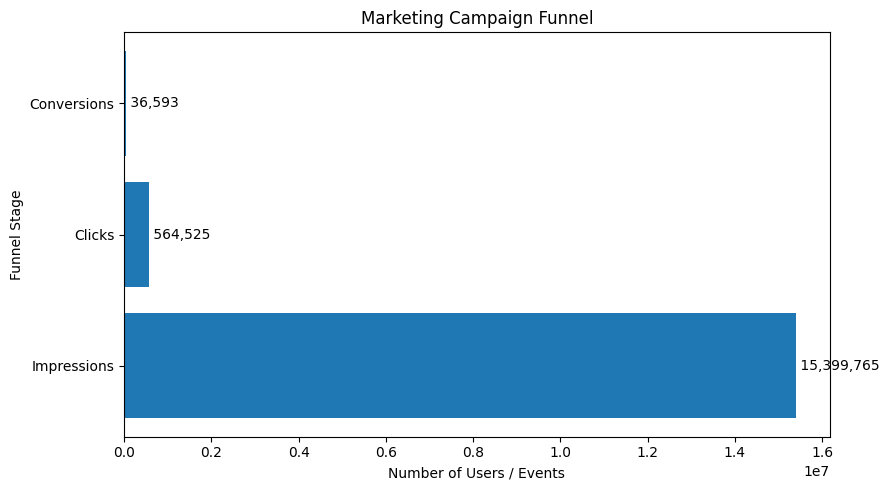

Click-through rate: 3.67%
Click-to-conversion rate: 6.48%


In [6]:

# Calculate overall funnel values
impressions = df["impressions"].sum()
clicks = df["clicks"].sum()
conversions = df["conversions"].sum()

stages = ["Impressions", "Clicks", "Conversions"]
values = [impressions, clicks, conversions]

plt.figure(figsize=(9, 5))
bars = plt.barh(stages, values)

plt.title("Marketing Campaign Funnel")
plt.xlabel("Number of Users / Events")
plt.ylabel("Funnel Stage")

for bar, value in zip(bars, values):
    plt.text(
        bar.get_width(),
        bar.get_y() + bar.get_height()/2,
        f" {value:,}",
        va="center"
    )

plt.tight_layout()
plt.show()

print(f"Click-through rate: {clicks / impressions * 100:.2f}%")
print(f"Click-to-conversion rate: {conversions / clicks * 100:.2f}%")


In [7]:

channel_summary = df.groupby("channel").agg(
    spend=("spend", "sum"),
    revenue=("revenue", "sum"),
    impressions=("impressions", "sum"),
    clicks=("clicks", "sum"),
    conversions=("conversions", "sum")
)

channel_summary["ROAS"] = (
    channel_summary["revenue"] /
    channel_summary["spend"].replace(0, np.nan)
)

channel_summary["ROI (%)"] = (
    (channel_summary["revenue"] - channel_summary["spend"]) /
    channel_summary["spend"].replace(0, np.nan) * 100
)

channel_summary["CPA"] = (
    channel_summary["spend"] /
    channel_summary["conversions"].replace(0, np.nan)
)

display(channel_summary.round(2))


,spend,revenue,impressions,clicks,conversions,ROAS,ROI (%),CPA
channel,,,,,,,,
Email Marketing,12162.75,676393.85,1187175,104047,10598,55.61,5461.19,1.15
Facebook Ads,30871.73,256334.90,2757789,88148,3723,8.30,730.32,8.29
Google Ads,41883.94,1534722.46,4552231,222601,14768,36.64,3564.23,2.84
Instagram Ads,26401.34,224031.74,2642305,75246,2889,8.49,748.56,9.14
LinkedIn Ads,43010.42,920941.80,4260265,74483,4615,21.41,2041.21,9.32


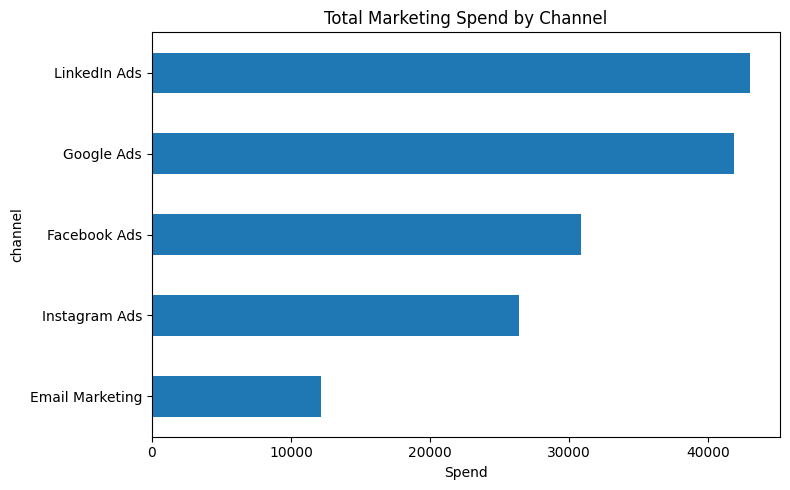

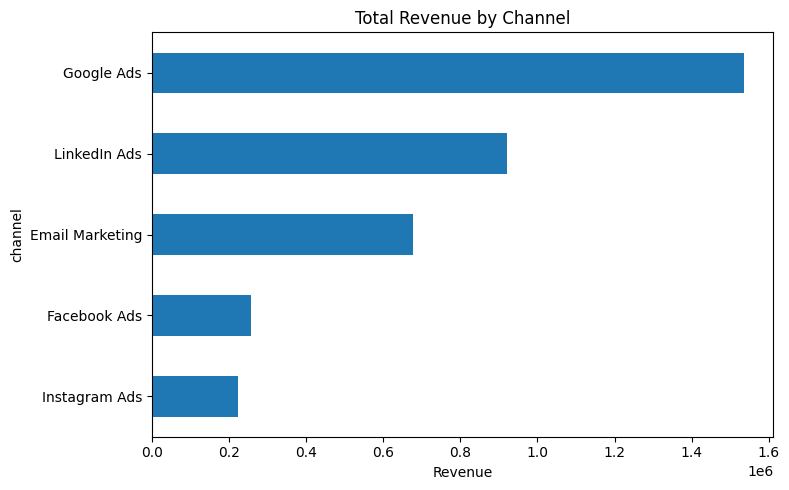

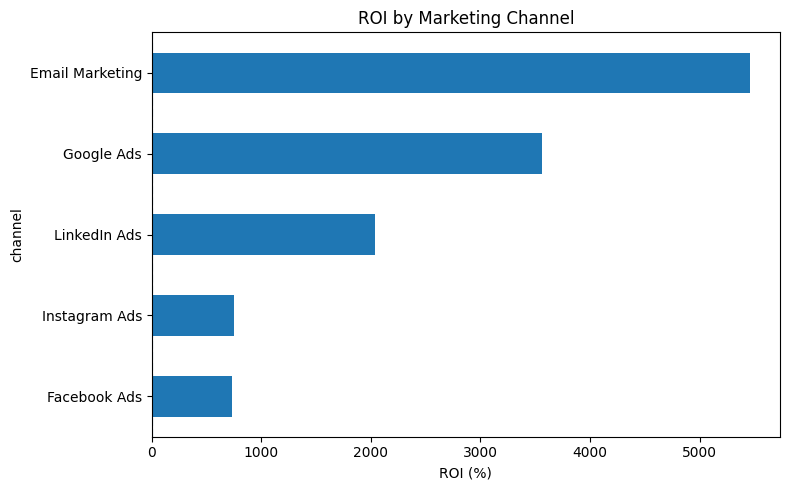

In [8]:

# Spending by channel
channel_summary["spend"].sort_values().plot(
    kind="barh", figsize=(8, 5),
    title="Total Marketing Spend by Channel"
)
plt.xlabel("Spend")
plt.tight_layout()
plt.show()

# Revenue by channel
channel_summary["revenue"].sort_values().plot(
    kind="barh", figsize=(8, 5),
    title="Total Revenue by Channel"
)
plt.xlabel("Revenue")
plt.tight_layout()
plt.show()

# ROI by channel
channel_summary["ROI (%)"].sort_values().plot(
    kind="barh", figsize=(8, 5),
    title="ROI by Marketing Channel"
)
plt.axvline(0, linestyle="--")
plt.xlabel("ROI (%)")
plt.tight_layout()
plt.show()


In [9]:

print("Channels ranked by ROAS:")
display(
    channel_summary.sort_values(
        "ROAS", ascending=False
    ).round(2)
)

print("\nBest ROAS channel:")
print(channel_summary["ROAS"].idxmax())

print("\nBest ROI channel:")
print(channel_summary["ROI (%)"].idxmax())

print("\nLowest CPA channel:")
print(channel_summary["CPA"].idxmin())


Channels ranked by ROAS:


,spend,revenue,impressions,clicks,conversions,ROAS,ROI (%),CPA
channel,,,,,,,,
Email Marketing,12162.75,676393.85,1187175,104047,10598,55.61,5461.19,1.15
Google Ads,41883.94,1534722.46,4552231,222601,14768,36.64,3564.23,2.84
LinkedIn Ads,43010.42,920941.80,4260265,74483,4615,21.41,2041.21,9.32
Instagram Ads,26401.34,224031.74,2642305,75246,2889,8.49,748.56,9.14
Facebook Ads,30871.73,256334.90,2757789,88148,3723,8.30,730.32,8.29



Best ROAS channel:
Email Marketing

Best ROI channel:
Email Marketing

Lowest CPA channel:
Email Marketing
